# Behavioral Repayment Decisions

## Alcance y pregunta

¿El costo inmediato de atención puede superar el efecto de una penalidad futura?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$C_{pago}=1.1-s,\quad C_{mora}=\beta\delta(1.4)$$

Cada deudor compara pagar hoy (costo inmediato de 1) con posponer (costo futuro 1.4) bajo descuento cuasi hiperbólico. Una intervención reduce un costo de fricción presente. Se evalúa la decisión individual, sin interpretar la simulación como un experimento conductual observado.

### Supuestos de identificación

Preferencias conocidas; sin restricción de liquidez; decisiones deterministas dada β; heterogeneidad uniforme.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Cada deudor compara pagar hoy (costo inmediato de 1) con posponer (costo futuro 1.4) bajo descuento cuasi hiperbólico. Una intervención reduce un costo de fricción presente. Se evalúa la decisión individual, sin interpretar la simulación como un experimento conductual observado.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=2000):
    beta=rng.uniform(.4,1,n);delta=.95
    cost_pay=1.1-level;cost_delay=beta*delta*1.4
    pay=cost_pay<=cost_delay
    rational=1.1-level<=delta*1.4
    return {'Fracción que paga':pay.mean(),'Agente exponencial paga':float(rational),
        'β crítico':cost_pay/(delta*1.4)},(beta,pay.astype(float))


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0, 0.05, 0.1, 0.2, 0.3]
METRICS=['Fracción que paga', 'Agente exponencial paga', 'β crítico']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.1 ; semilla: 20261018


,Métrica,Valor
0,Fracción que paga,0.42750
1,Agente exponencial paga,1.00000
2,β crítico,0.75188


## Sensibilidad y variación entre réplicas

**Eje:** Reducción de fricción presente.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.00,Fracción que paga,0.28638,0.28600,0.00984,0.26791,0.30452,40,0.00156
1,0.00,Agente exponencial paga,1.00000,1.00000,0.00000,1.00000,1.00000,40,0.00000
2,0.00,β crítico,0.82707,0.82707,0.00000,0.82707,0.82707,40,0.00000
3,0.05,Fracción que paga,0.34855,0.34950,0.01087,0.32736,0.36904,40,0.00172
4,0.05,Agente exponencial paga,1.00000,1.00000,0.00000,1.00000,1.00000,40,0.00000
5,0.05,β crítico,0.78947,0.78947,0.00000,0.78947,0.78947,40,0.00000
6,0.10,Fracción que paga,0.41112,0.40950,0.01138,0.38990,0.43172,40,0.00180
7,0.10,Agente exponencial paga,1.00000,1.00000,0.00000,1.00000,1.00000,40,0.00000
8,0.10,β crítico,0.75188,0.75188,0.00000,0.75188,0.75188,40,0.00000
9,0.20,Fracción que paga,0.53580,0.53325,0.01179,0.51447,0.55974,40,0.00186


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

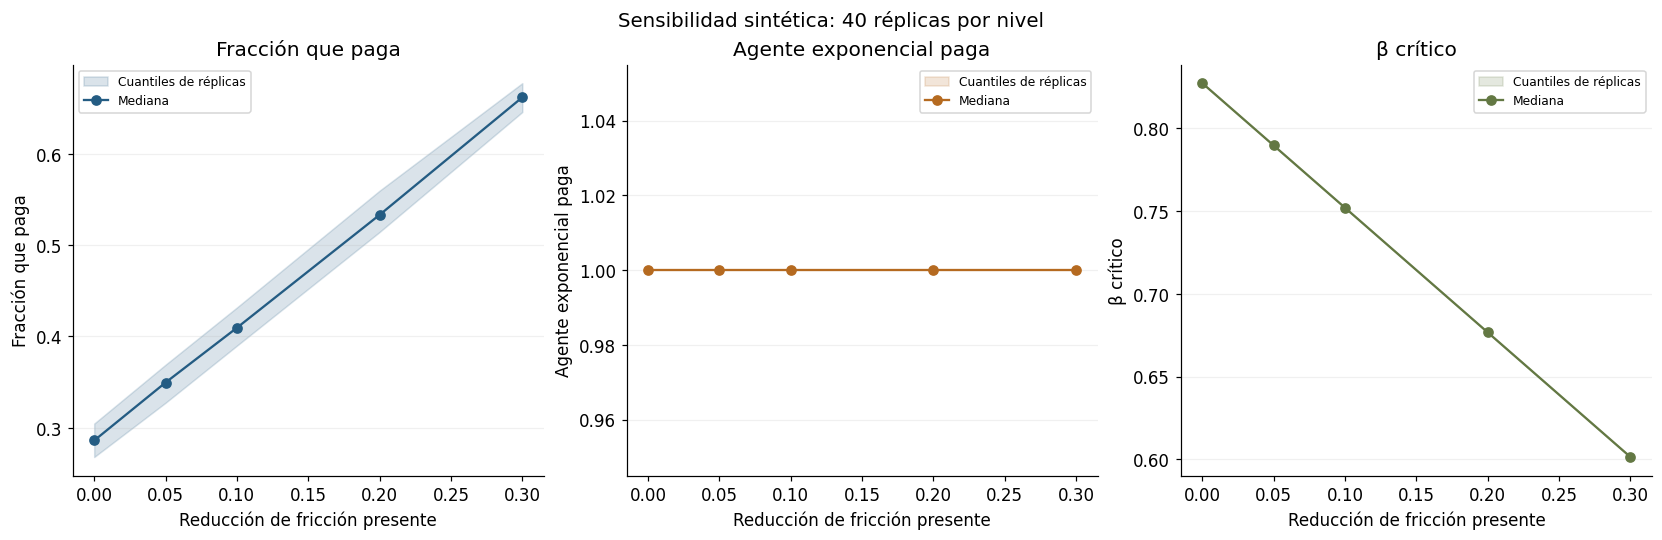

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Reducción de fricción presente',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


Fracción que paga: mediana 0.286 en nivel 0; 0.662 en nivel 0.3.
  Último escenario: cuantiles [0.645925, 0.677525], media 0.661725, error MC de la media 0.00154.
Agente exponencial paga: mediana 1 en nivel 0; 1 en nivel 0.3.
  Último escenario: cuantiles [1, 1], media 1, error MC de la media 0.
β crítico: mediana 0.827068 en nivel 0; 0.601504 en nivel 0.3.
  Último escenario: cuantiles [0.601504, 0.601504], media 0.601504, error MC de la media 0.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

No se identifica sesgo presente a partir de mora observada. Falta separar iliquidez de preferencias y probar la intervención con datos.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.